# Q1
## A

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def compare_histograms(sample_size=200, bins=30):
    # Generate datasets
    normal_dataset = np.random.normal(2, 1, sample_size)
    exp_dataset = np.exp(np.random.normal(0, 1, sample_size))
    
    # using plt
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.hist(normal_dataset, bins=bins, alpha=0.7, label='Normal(2,1)')
    plt.hist(exp_dataset, bins=bins, alpha=0.7, label='exp(N(0,1))')
    plt.title("Matplotlib Histogram")
    plt.legend()

    # using numpy
    plt.subplot(1,2,2)
    counts1, bin_edges1 = np.histogram(normal_dataset, bins=bins)
    counts2, bin_edges2 = np.histogram(exp_dataset, bins=bins)
    
    plt.bar(bin_edges1[:-1], counts1, width=np.diff(bin_edges1), alpha=0.7, label='Normal(2,1)')
    plt.bar(bin_edges2[:-1], counts2, width=np.diff(bin_edges2), alpha=0.7, label='exp(N(0,1))')
    plt.title("NumPy Histogram (Manual)")
    plt.legend()
    
    plt.tight_layout()
    plt.show()

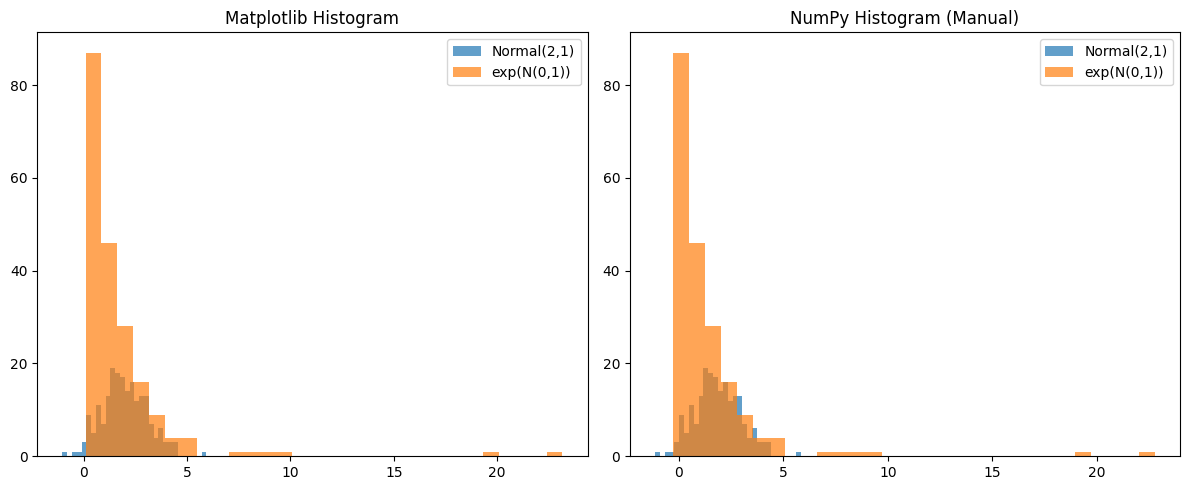

In [4]:
compare_histograms()

The Matplotlib method provides better interpretability and divisibility because it automatically selects appropriate bin sizes, generates clear and visually intuitive histograms, and makes it easier to compare distributions.
In contrast, the NumPy method is more analytical and requires manual plotting, making it less visually understandable.

## B

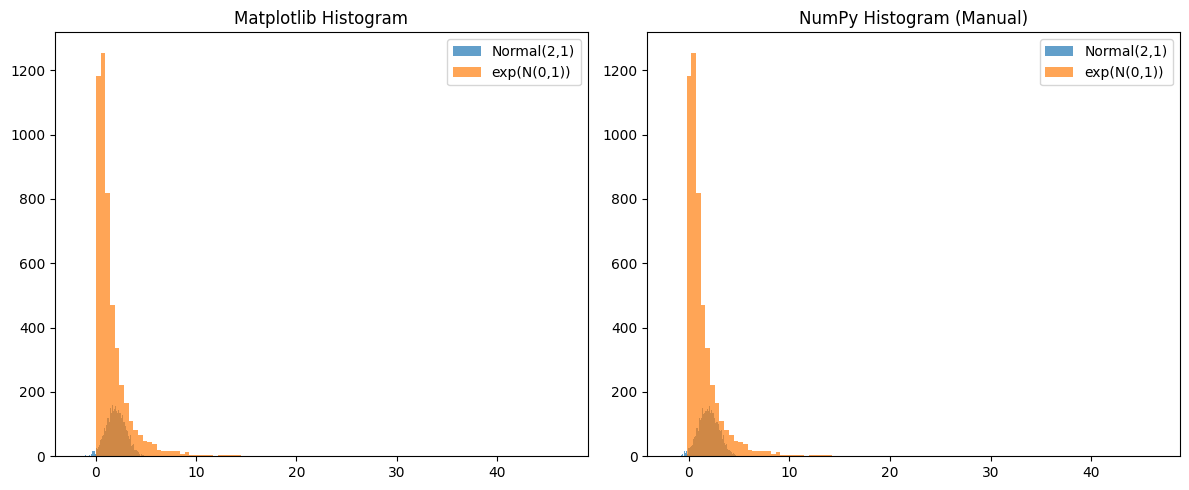

In [5]:
compare_histograms(5000, 100)

## C
No, increasing the number of bins is not always beneficial.
If the number of bins is too large, each bin contains few data points, making the histogram noisy and hard to interpret.
If it’s too small, important details of the distribution are lost.
The number of bins should balance smoothness and detail.

# Q2

skewness: 0.04


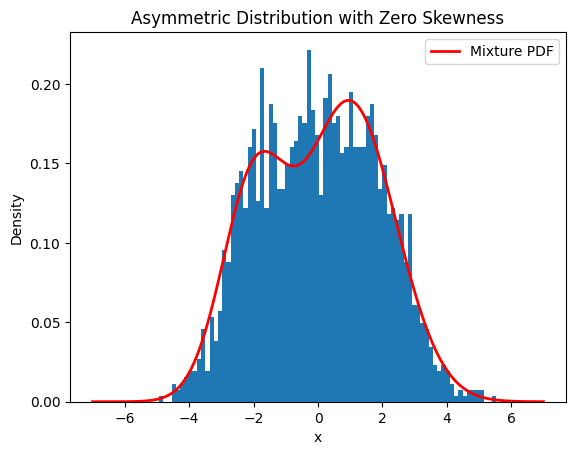

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skew

c1, c2 = 1/3, 2/3
mu1, mu2 = -2, 1
sigma1, sigma2 = 1, np.sqrt(2)

n = 2000
choices = np.random.choice([1, 2], size=n, p=[c1, c2])

samples = np.where(
    choices == 1,
    np.random.normal(mu1, sigma1, n),
    np.random.normal(mu2, sigma2, n)
)

# calculate skewness
skewness = skew(samples)
print(f"skewness: {skewness:.2f}")

plt.hist(samples, bins=80, density=True)
# Overlay true mixture density
x = np.linspace(-7, 7, 500)
f = c1 * norm.pdf(x, mu1, sigma1) + c2 * norm.pdf(x, mu2, sigma2)
plt.plot(x, f, 'r-', lw=2, label='Mixture PDF')

plt.title("Asymmetric Distribution with Zero Skewness")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.show()

Skewness is about zero, and the distribution is clearly not symmetric.

# Q3

In [49]:
from scipy.stats import t, kurtosis

df1, df2 = 2, 3
data1 = t.rvs(df1, size=100000)
data2 = t.rvs(df2, size=100000)

print("Empirical kurtosis (df=2):", kurtosis(data1, fisher=False))
print("Empirical kurtosis (df=3):", kurtosis(data2, fisher=False))

kurt1 = t.stats(df1, moments='k')
kurt2 = t.stats(df2, moments='k')

print(f"Theoretical kurtosis (df=2): {kurt1}")
print(f"Theoretical kurtosis (df=3): {kurt2}")

Empirical kurtosis (df=2): 864.0589046698399
Empirical kurtosis (df=3): 61.6012877994346
Theoretical kurtosis (df=2): nan
Theoretical kurtosis (df=3): inf


the exam corresponding to df = 2 is harder.
- It shows extremely high kurtosis → very heavy tails and large score variability.
- Some students score very low while a few score very high, suggesting high difficulty and strong discrimination power.

In contrast, the df = 3 distribution is closer to normal:
- Lower kurtosis → lighter tails, fewer extreme scores.
- More students perform around the mean.
- Therefore, it represents a more standardized and fair exam.

=> The df = 2 was harder, and the df = 3 is more standardized.

# Q4

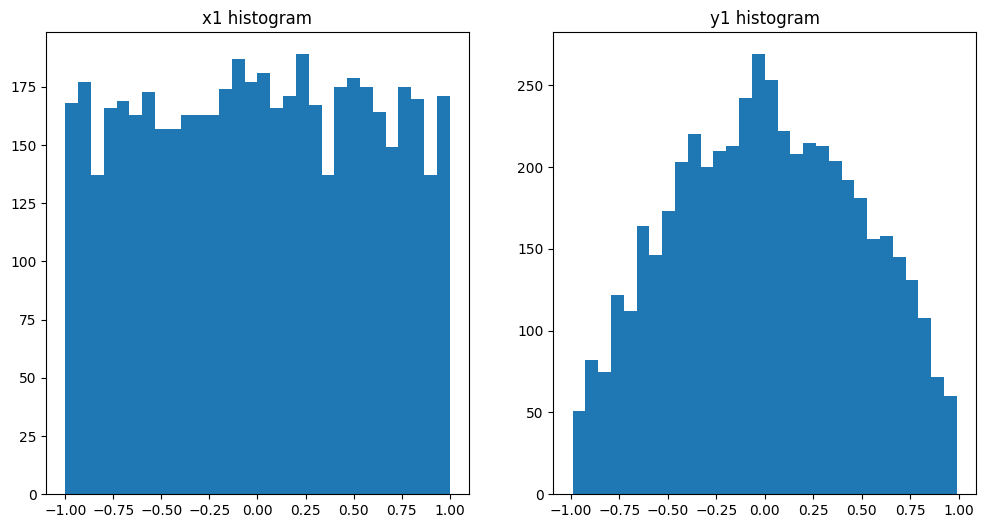

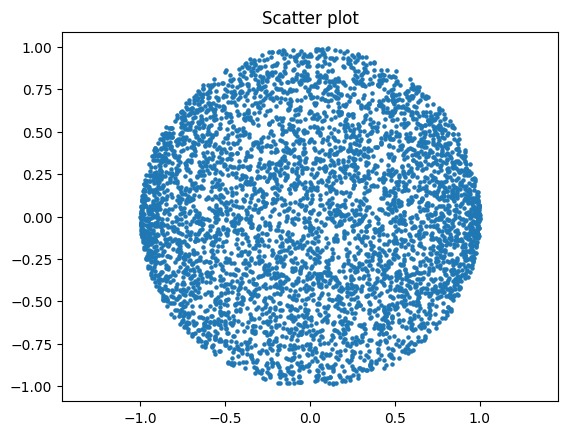

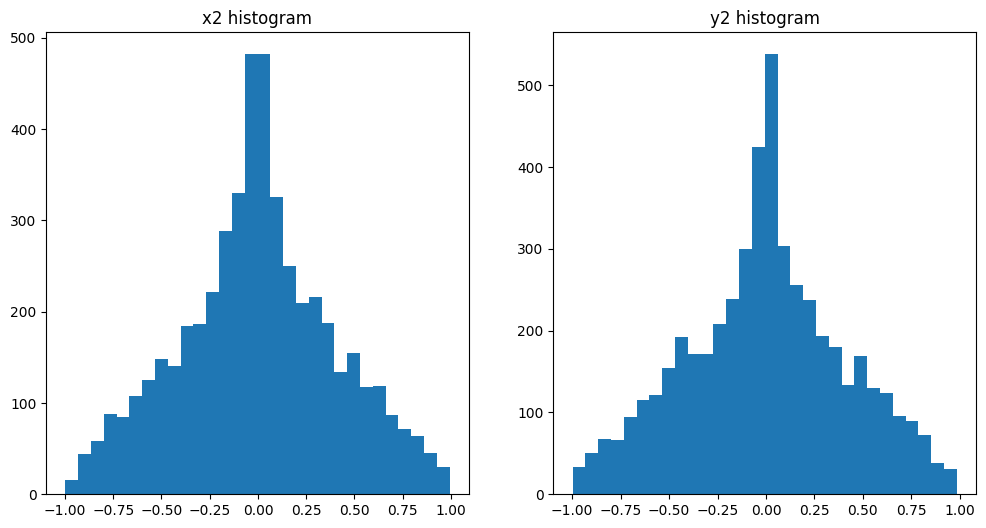

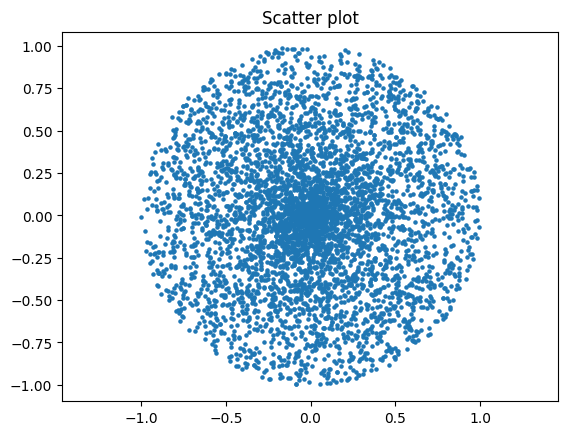

In [66]:
import numpy as np
import matplotlib.pyplot as plt

n = 5000
# --- part 1 ---
x1 = np.random.uniform(-1, 1, n)
y1 = np.random.uniform(-np.sqrt(1 - x1**2), np.sqrt(1 - x1**2), n)

# histograms
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.hist(x1, bins=30)
ax1.set_title("x1 histogram")

ax2 = fig.add_subplot(1, 2, 2)
ax2.hist(y1, bins=30)
ax2.set_title("y1 histogram")

plt.show()

# scatter plot
plt.figure()
plt.scatter(x1, y1, s=5)
plt.axis("equal")
plt.title("Scatter plot")
plt.show()

# --- part 2 ---
r = np.random.uniform(0, 1, n)
theta = np.random.uniform(-np.pi, np.pi, n)
x2 = r * np.sin(theta)
y2 = r * np.cos(theta)

# histograms
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.hist(x2, bins=30)
ax1.set_title("x2 histogram")

ax2 = fig.add_subplot(1, 2, 2)
ax2.hist(y2, bins=30)
ax2.set_title("y2 histogram")

plt.show()

# scatter plot
plt.figure()
plt.scatter(x2, y2, s=5)
plt.axis("equal")
plt.title("Scatter plot")
plt.show()

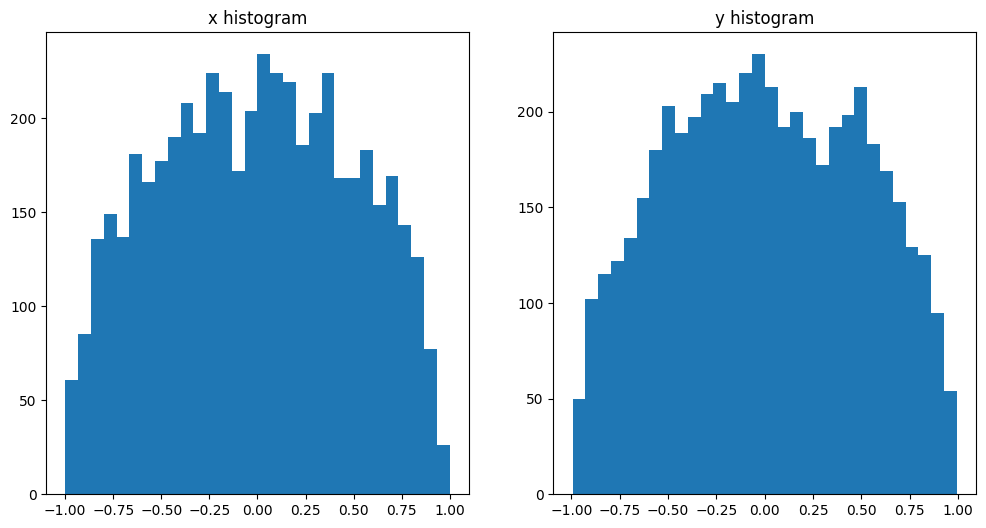

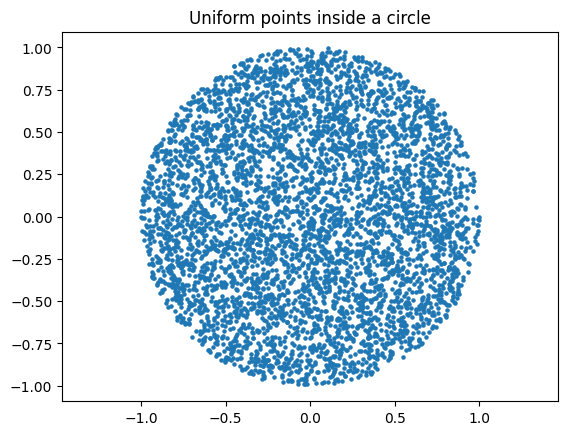

In [69]:
# *** The proposed method ***
r = np.sqrt(np.random.uniform(0, 1, n))   # sqrt ensures uniform area
theta = np.random.uniform(-np.pi, np.pi, n)

x = r * np.cos(theta)
y = r * np.sin(theta)

# histograms
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.hist(x, bins=30)
ax1.set_title("x histogram")

ax2 = fig.add_subplot(1, 2, 2)
ax2.hist(y, bins=30)
ax2.set_title("y histogram")

plt.show()

# scatter plot
plt.figure()
plt.scatter(x, y, s=5)
plt.axis("equal")
plt.title("Uniform points inside a circle")
plt.show()

Why are the first two methods not suitable?

1. The joint density over the 2-D region isn’t constant.
Each value of x is equally likely, but the allowable range of y (the vertical height of the circle at that x) changes with x.
Near the edges (|x| ~ 1), that range is small, while near the center it’s large. yet all x values are weighted equally.
As a result, points become denser near the sides (|x| large) and sparser near the center, so the area density is not uniform.
The histogram of x appears flat, but the histogram of y looks slightly bell-shaped, and the scatter plot shows a mild edge-bias rather than a perfectly even fill.

2. If r is uniform in [0, 1], then the area of a ring of radius r is 2πrdr.
Uniform r gives equal probability to each radial band of width dr, but since the area of each ring grows with r, larger rings get too few points.
Hence the density increases toward the center, not uniform in area.
The scatter plot looks circular but with a bright cluster at the middle, and both histograms of x and y are bell-shaped.

- Why the proposed method works:
Uniform r is wrong because a ring of radius r has circumference 2πr: more points are needed as r increases to keep the area density constant.
By taking r=sqrt(U), the density compensates for that r factor, giving equal probability per unit area.
Thus the scatter plot appears uniformly filled across the entire circle.